<a href="https://colab.research.google.com/github/shresta-28/TSA_DataScienceandAnalytics/blob/main/ev_strain_dataScience_TSA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction and Problem Statement

## Overview
###### As EV adoption increases throughout Washington state neighborhoods, local power grids can face strain in peak charging times. This project analyzes electrical grid data to quantify electricity demand and stress caused by EV charging, and evaluate how much an overnight discount can decrease such stress.

In [105]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ev_grid_og = pd.read_csv("ev_grid_dataset.csv")

# Data Processing and Cleaning

## Handling Missing Data
To maintain dataset integrity, missing values were treated using median imputation.

## Outlier Treatment
Outliers were found by checking what rows had a load column that was more than 120% of the median, or less than 50%. After tracking all anomalies to the "outlier_log.csv", they are replaced with the median of that column.

## Recalculating Columns
To make sure totals align after data cleaning, derived metrics were recalculated. "EV_Charging_Load_MW" combined home and public EV charging load. "Total_Load_MW" combines base load and total EV charging load.

In [106]:
ev_grid_working = ev_grid_og.copy()

def count_blanks(data):
  """
  This is a utility function that checks for missing values across the dataset.
  It targets Temperature and Charging infrastructure, since that is where the real world gaps in data would likely lie,
  as well as checking the electrical load columns for missing values.

  Parameters:
    data (pd.DataFrame): DataFrame containing the records to check
  """
  print("Blanks in Avg_Temp_F:", data["Avg_Temp_F"].isna().sum())
  print("Blanks in Public_Charger_Count:", data["Public_Charger_Count"].isna().sum())

  load_cols = ["Base_Load_MW", "Home_EV_Load_MW", "Public_EV_Load_MW",
              "EV_Charging_Load_MW", "Total_Load_MW"]
  print("Blanks in load columns (should be 0):\n", data[load_cols].isna().sum())

  blanks_before = data.isna().sum()
  rows_before = len(data)
  print("All columns with blanks:\n", blanks_before[blanks_before > 0])
count_blanks(ev_grid_og)

Blanks in Avg_Temp_F: 54
Blanks in Public_Charger_Count: 54
Blanks in load columns (should be 0):
 Base_Load_MW           0
Home_EV_Load_MW        0
Public_EV_Load_MW      0
EV_Charging_Load_MW    0
Total_Load_MW          0
dtype: int64
All columns with blanks:
 Public_Charger_Count    54
Avg_Temp_F              54
dtype: int64


In [107]:
typical_temp = ev_grid_working.groupby(["Month", "Time_Block"])["Avg_Temp_F"].transform("median")
ev_grid_working["Avg_Temp_F"] = ev_grid_working["Avg_Temp_F"].fillna(typical_temp).round(1)

typical_chargers = ev_grid_working.groupby(["Zone_ID", "Year", "Month"])["Public_Charger_Count"].transform("median")
ev_grid_working["Public_Charger_Count"] = ev_grid_working["Public_Charger_Count"].fillna(typical_chargers).round()

# Checks that blanks were successfully removed before continuing
count_blanks(ev_grid_working)


Blanks in Avg_Temp_F: 0
Blanks in Public_Charger_Count: 0
Blanks in load columns (should be 0):
 Base_Load_MW           0
Home_EV_Load_MW        0
Public_EV_Load_MW      0
EV_Charging_Load_MW    0
Total_Load_MW          0
dtype: int64
All columns with blanks:
 Series([], dtype: int64)


In [108]:
def find_outliers(check_cols, data):
  """
  Identifies outliers by comparing actual column values with target values

  Parameters:
    check_cols (dict): Dictionary that maps column names to median scores to act as the target values
    data (pd.DataFrame): DataFrame containing the records to check

  Returns:
    dict: Masks rows with boolean values indicating outlier rows
  """
  outliers={}
  for col in check_cols:
    ratio = data[col] / check_cols[col]
    # Tags anything above 140% or below 50% as anomalies
    outliers[col] = (ratio>1.4) | (ratio < 0.5)
    print(f"Total Outliers for {col} = {outliers[col].sum()}")
  return outliers

In [109]:
typical_base_load = ev_grid_working.groupby(["Zone_ID", "Month", "Time_Block"])["Base_Load_MW"].transform("median")
typical_home_load = ev_grid_working.groupby(["Zone_ID", "Year", "Time_Block", "Discount_Active"])["Home_EV_Load_MW"].transform("median")
typical_public_load = ev_grid_working.groupby(["Zone_ID", "Year", "Time_Block", "Discount_Active"])["Public_EV_Load_MW"].transform("median")

outlier_possible_cols = {"Base_Load_MW":typical_base_load, "Home_EV_Load_MW":typical_home_load, "Public_EV_Load_MW":typical_public_load}
outlier_rows = find_outliers(outlier_possible_cols, ev_grid_working)

# Replaces outliers with median values of said column
log = []
for col in outlier_possible_cols:
    typicals = outlier_possible_cols[col]
    for i in ev_grid_working.index[outlier_rows[col]]:
        log.append({"Row_ID": ev_grid_working.at[i, "Row_ID"], "Column": col,
                    "Old_Value": ev_grid_working.at[i, col],
                    "New_Value": round(typicals[i], 3)})
    ev_grid_working.loc[outlier_rows[col], col] = typicals[outlier_rows[col]].round(3)

log_df = pd.DataFrame(log)
log_df.to_csv("outlier_log.csv", index=False)
print(len(log_df), "outliers fixed")

Total Outliers for Base_Load_MW = 27
Total Outliers for Home_EV_Load_MW = 40
Total Outliers for Public_EV_Load_MW = 30
97 outliers fixed


In [110]:
# Recalculates dependant columns to match with adjusted values
ev_grid_working["EV_Charging_Load_MW"] = (ev_grid_working["Home_EV_Load_MW"] + ev_grid_working["Public_EV_Load_MW"]).round(3)
ev_grid_working["Total_Load_MW"] = (ev_grid_working["Base_Load_MW"] + ev_grid_working["EV_Charging_Load_MW"]).round(3)
print(ev_grid_working)

      Row_ID Zone_ID      Zone_Name  Year  Month    Time_Block  Homes_in_Zone  \
0          1     Z01       Bellevue  2019      1       Morning           1500   
1          2     Z01       Bellevue  2019      1     Afternoon           1500   
2          3     Z01       Bellevue  2019      1  Evening_Peak           1500   
3          4     Z01       Bellevue  2019      1     Overnight           1500   
4          5     Z01       Bellevue  2019      2       Morning           1500   
...      ...     ...            ...   ...    ...           ...            ...   
5371    5372     Z16  Battle Ground  2025     11     Overnight            639   
5372    5373     Z16  Battle Ground  2025     12       Morning            639   
5373    5374     Z16  Battle Ground  2025     12     Afternoon            639   
5374    5375     Z16  Battle Ground  2025     12  Evening_Peak            639   
5375    5376     Z16  Battle Ground  2025     12     Overnight            639   

      EV_Share_Pct  Public_

# Exploratory Data Analysis

## Extra Features
To prepare for data analysis, extra columns were made.
1. 'Date' with a DateTime format.
2. 'Home_EV_Cap_Pct' shows how much the Home EV charging takes up the grid load capacity
3. 'Stress_Per_E' shows how much each EV adds up to the stress level that EV charging takes up
4. 'Policy_Status' reworks the Policy_Active column to be ready for use in data analysis
5. 'Total_Stress_Pct' shows how much the total load takes up of the avaiable total grid capacity.

## Data Analysis and Graphs
* Line plots and heatmaps were used to confirm Evening Peak hours straining the electrical grid
* Linear regression maps were used to show how the weather and temperature impacts Base Laod
* Bar charts show how EV adoption percentages change across policy zones and how it affects stress

In [111]:
import matplotlib.patches as mpatches

ev_grid_working["Date"] = pd.to_datetime(
    ev_grid_working["Year"].astype(str) + "-" + ev_grid_working["Month"].astype(str).str.zfill(2) + "-01"
)

ev_grid_working["Home_EV_Cap_Pct"] = (ev_grid_working["Home_EV_Load_MW"] / ev_grid_working["Grid_Capacity_MW"]) * 100
ev_grid_working["Stress_Per_EV"] = ev_grid_working["Home_EV_Cap_Pct"]/ev_grid_working["EV_Share_Pct"]
ev_grid_working["Policy_Status"] = ev_grid_working["Discount_Active"].map(
    {"Yes": "Discount Active", "No": "No Discount"}
)

policy_zones = set(
    ev_grid_working[ev_grid_working["Discount_Active"] == "Yes"][
        "Zone_Name"
    ].unique()
)

ev_grid_working["Total_Stress_Pct"] = ( ev_grid_working["Total_Load_MW"] / ev_grid_working["Grid_Capacity_MW"] ) * 100

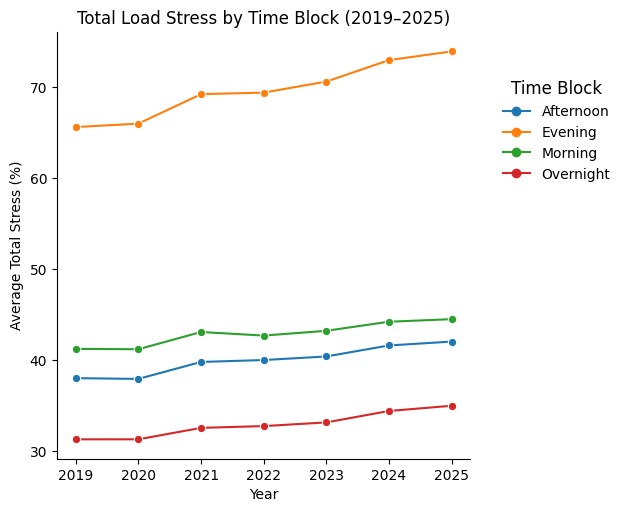

In [112]:
# This line graph quickly demonstrates the huge gap between stress in evening time blocks versus other time blocks
yearly_load = (
    ev_grid_working.set_index("Date")
    .groupby("Time_Block")["Total_Stress_Pct"]
    .resample("YS")
    .mean()
    .reset_index()
)

yearly_total_load_graph=sns.relplot(yearly_load, x="Date", y="Total_Stress_Pct", hue="Time_Block", kind="line", marker="o")
yearly_total_load_graph.set(title="Total Load Stress by Time Block (2019–2025)", ylabel="Average Total Stress (%)", xlabel="Year")
sns.move_legend(yearly_total_load_graph,  loc="upper right",
    title="Time Block",
    labels=["Afternoon", "Evening", "Morning", "Overnight"],
    bbox_to_anchor=(1, 0.9),
    fontsize=10,
    title_fontsize=12)
plt.savefig("yearly_total_load_graph.png", dpi=300, bbox_inches="tight")

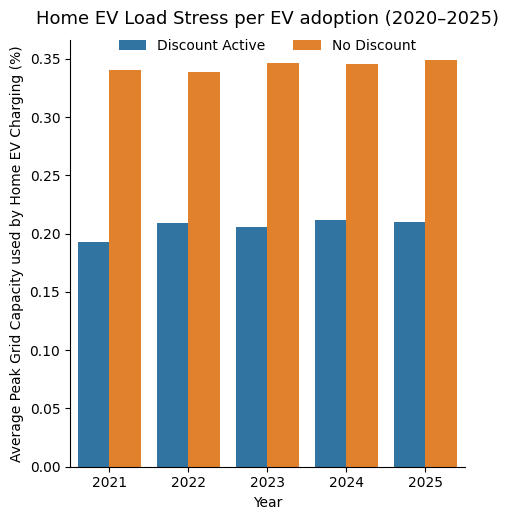

In [113]:
# This bar graph verifies that discount reduces stress caused by increasing EV adoptions
yearly_evening_byPolicy = (
    ev_grid_working[(ev_grid_working["Time_Block"] == "Evening_Peak") & (ev_grid_working["Year"] > 2020)]
    .groupby(["Year", "Policy_Status"])["Stress_Per_EV"]
    .mean()
    .reset_index()
)
yearly_evening_byPolicy_graph = sns.catplot(yearly_evening_byPolicy, x="Year", y="Stress_Per_EV", hue="Policy_Status", kind="bar")
yearly_evening_byPolicy_graph.set(xlabel = "Year", ylabel="Average Peak Grid Capacity used by Home EV Charging (%)")
yearly_evening_byPolicy_graph.fig.suptitle(
    "Home EV Load Stress per EV adoption (2020–2025)", y=1.03, x=0.45, fontsize=13
)
sns.move_legend(yearly_evening_byPolicy_graph,  loc="lower center",
    title=None,
    bbox_to_anchor=(0.45, 0.92),
    ncol=2,
    fontsize=10,
    title_fontsize=12)
plt.savefig("yearly_evening_byPolicy_graph.png", dpi=300, bbox_inches="tight")

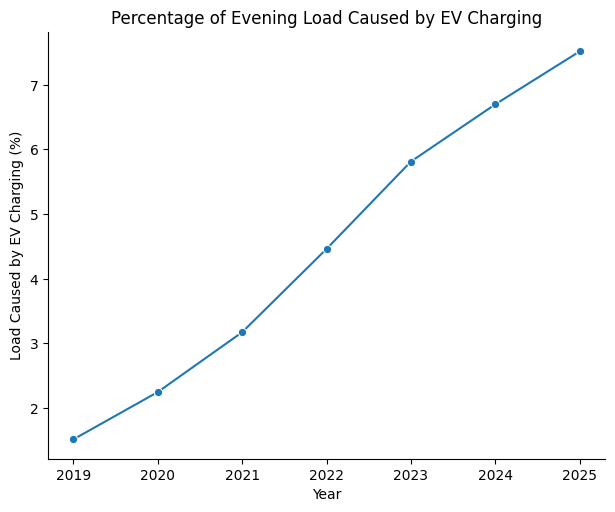

In [114]:
# This line graph clearly shows that EV charging does play an increasing part in the evening peak grid stress
evening_load = ev_grid_working[
    ev_grid_working["Time_Block"] == "Evening_Peak"
].copy()

evening_load["EV_Caused_Load_Pct"] = (evening_load["EV_Charging_Load_MW"] / evening_load["Total_Load_MW"]) * 100
evening_load_mean = evening_load.groupby("Year")["EV_Caused_Load_Pct"].mean()
ev_caused_load_graph = sns.relplot(pd.DataFrame(evening_load_mean), y="EV_Caused_Load_Pct", x="Year", kind="line", marker="o", aspect=10/8)
ev_caused_load_graph.set(title="Percentage of Evening Load Caused by EV Charging", xlabel="Year", ylabel="Load Caused by EV Charging (%)")
plt.savefig("ev_caused_load_graph.png", dpi=300, bbox_inches="tight")

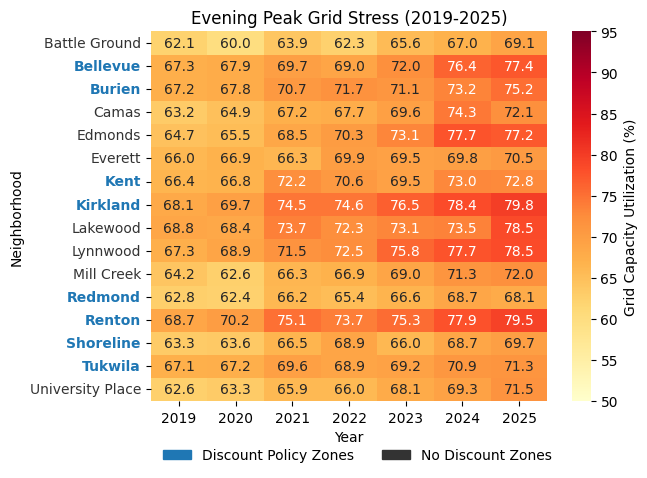

In [98]:
# This annotated heatmap can show detailed zone-by-zone increasing evening stress levels
total_stress_table = ev_grid_working[ev_grid_working["Time_Block"]=="Evening_Peak"].pivot_table(
  index="Zone_Name", columns="Year", values="Total_Stress_Pct", aggfunc="mean"
)

total_stress_graph = sns.heatmap(
  total_stress_table,
  annot=True,
  fmt=".1f",
  cmap="YlOrRd",
  vmin=50,
  vmax=95,
  cbar_kws={"label": "Grid Capacity Utilization (%)"},
)

total_stress_graph.set(title="Evening Peak Grid Stress (2019-2025)", xlabel="Year", ylabel="Neighborhood")

for tick_label in total_stress_graph.get_yticklabels():
  zone_name = tick_label.get_text()
  if zone_name in policy_zones:
    tick_label.set_color("#1f77b4")
    tick_label.set_fontweight("bold")
  else:
    tick_label.set_color("#333333")

policy_patch = mpatches.Patch(
  color="#1f77b4", label="Discount Policy Zones"
)

control_patch = mpatches.Patch(
  color="#333333", label="No Discount Zones"
)

total_stress_graph.legend(
  handles=[policy_patch, control_patch],
  loc="lower left",
  bbox_to_anchor=(0, -0.2),
  ncol=2,
  frameon=False,
)

plt.savefig("total_stress_graph.png", dpi=300, bbox_inches="tight")

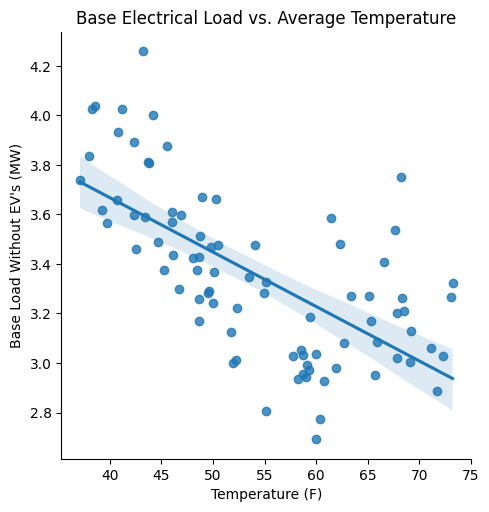

In [99]:
# This regression line graph verifies that weather affects the base electrical load and could affect stress levels
base_load_weather_graph = sns.lmplot(ev_grid_working[(ev_grid_working["Zone_Name"] == "Bellevue") & (ev_grid_working["Time_Block"]=="Evening_Peak")], x="Avg_Temp_F", y="Base_Load_MW")
base_load_weather_graph.set(title="Base Electrical Load vs. Average Temperature", xlabel="Temperature (F)", ylabel="Base Load Without EV's (MW)")
plt.savefig("base_load_weather_graph.png", dpi=300, bbox_inches="tight")

# Machine Learning and Counterfactual Simulations

## Predictive Modeling
* A RandomForestRegressor was used to model and predict total grid stress based on neighborhood and policy characteristics.
* Features: Home counts, EV counts, Charger counts, Temperature, Grid Capacity, Policy, and Time Block.
* The model was evaluated by testing the previously split testing data and getting the root mean squared error (RMSE) of 3.176% and R^2 value of 0.953
## Modeling Use

After testing, the model was used to predict counterfactual situations where policy zones were switched to understand how that would affect total grid stress levels.

In [100]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np

# Changes categorical features to numeric to be able to include in model
ev_grid_working["Policy_Numeric"] = ev_grid_working["Discount_Active"].map({"Yes": 1, "No": 0})

evening_data = ev_grid_working[ev_grid_working["Time_Block"] == "Evening_Peak"].copy()

features = [
    "Homes_in_Zone",
    "EV_Share_Pct",
    "Public_Charger_Count",
    "Avg_Temp_F",
    "Grid_Capacity_MW",
    "Policy_Numeric",
]
target = "Total_Stress_Pct"

X = evening_data[features]
Y = evening_data[target]

# Splits testing and training data to simulate new data and understand model accuracy
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# Uses random_state 42 to ensure reproducibility
discount_simulation_model = RandomForestRegressor(n_estimators=100, random_state=42)
discount_simulation_model.fit(X_train, Y_train)
y_pred = discount_simulation_model.predict(X_test)

# Evaluates accuracy of model
print(f"Model R² Score: {r2_score(Y_test, y_pred):.3f}")
print(
    f"Model Root Mean Squared Error (RMSE):"
    f" {np.sqrt(mean_squared_error(Y_test, y_pred)):.3f}%"
)

print (discount_simulation_model.feature_importances_)

Model R² Score: 0.651
Model Root Mean Squared Error (RMSE): 4.896%
[0.09339436 0.09579922 0.1005308  0.64556065 0.05975258 0.00496239]


In [101]:
def predict_policy_impact(neighborhood_name):
  """
  This method predicts the impact implementing a policy would have in growth around 3 years after 2025 in a given neighborhood during the Evening time block

  Parameters:
    neighborhood_name (string): Describes which neighborhood to simulate

  Returns:
    float: Amount of stress reduced, by percentage of capacity
  """
  latest_data = ev_grid_working[ev_grid_working["Zone_Name"] == neighborhood_name].iloc[-1].copy()

  # Changes features to simulate growth that would happen in around 3 years
  future_ev_share = min(50.0, latest_data["EV_Share_Pct"] * 1.5)
  scenario_no_policy = pd.DataFrame([{
        "Homes_in_Zone": latest_data["Homes_in_Zone"] * 1.05,
        "EV_Share_Pct": future_ev_share,
        "Public_Charger_Count": latest_data["Public_Charger_Count"] + 5,
        "Avg_Temp_F": latest_data["Avg_Temp_F"],
        "Grid_Capacity_MW": latest_data["Grid_Capacity_MW"],
        "Policy_Numeric": 0,
  }])

  scenario_with_policy = scenario_no_policy.copy()
  scenario_with_policy["Policy_Numeric"] = 1

  # Predicts policy and no policy scenarios in 3 years
  stress_no_policy = discount_simulation_model.predict(scenario_no_policy)[0]
  stress_with_policy = discount_simulation_model.predict(scenario_with_policy)[0]
  stress_reduction = stress_no_policy - stress_with_policy

  print(f"Estimated Grid Stress without discount: {stress_no_policy: 0.2f}% of capacity")
  print(f"Estimated Grid Stress with discount: {stress_with_policy: 0.2f}% of capacity")
  print(f"Estimated Grid Stress Reduction with Policy: {stress_reduction: 0.2f}% of capacity")
  return stress_reduction

--------Mill Creek Impact--------
Estimated Grid Stress without discount:  86.68% of capacity
Estimated Grid Stress with discount:  86.60% of capacity
Estimated Grid Stress Reduction with Policy:  0.08% of capacity
--------Lynnwood Impact--------
Estimated Grid Stress without discount:  89.99% of capacity
Estimated Grid Stress with discount:  89.47% of capacity
Estimated Grid Stress Reduction with Policy:  0.52% of capacity
--------Edmonds Impact--------
Estimated Grid Stress without discount:  86.73% of capacity
Estimated Grid Stress with discount:  86.50% of capacity
Estimated Grid Stress Reduction with Policy:  0.23% of capacity
--------Everett Impact--------
Estimated Grid Stress without discount:  88.18% of capacity
Estimated Grid Stress with discount:  87.53% of capacity
Estimated Grid Stress Reduction with Policy:  0.64% of capacity
--------Lakewood Impact--------
Estimated Grid Stress without discount:  90.48% of capacity
Estimated Grid Stress with discount:  90.02% of capacity

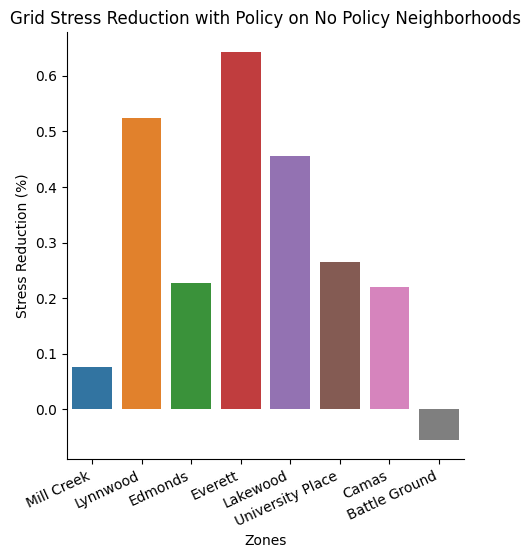

In [102]:
# Checks each no policy zone to see if implementing a policy would benefit stress levels in 3 years
discount_simulations = []
no_policy = ev_grid_working[~ev_grid_working["Zone_Name"].isin(policy_zones)]["Zone_Name"].unique()
for zone in no_policy:
    print(f"--------{zone} Impact--------")
    discount_simulations.append({"Zone_Name": zone, "Stress_Reduction": predict_policy_impact(zone)})
discount_simulations_dataframe = pd.DataFrame(discount_simulations)
discount_simulations_dataframe.to_csv("policy_impact_results.csv", index=False)
stress_reduction_with_policy_fake_graph = sns.catplot(discount_simulations_dataframe, kind="bar", y="Stress_Reduction", x="Zone_Name", hue="Zone_Name")
stress_reduction_with_policy_fake_graph.set(title="Grid Stress Reduction with Policy on No Policy Neighborhoods", xlabel="Zones", ylabel="Stress Reduction (%)")
stress_reduction_with_policy_fake_graph.set_xticklabels(rotation=25, horizontalalignment="right")
plt.savefig("stress_reduction_with_fake_policy_graph.png", dpi=300, bbox_inches="tight")

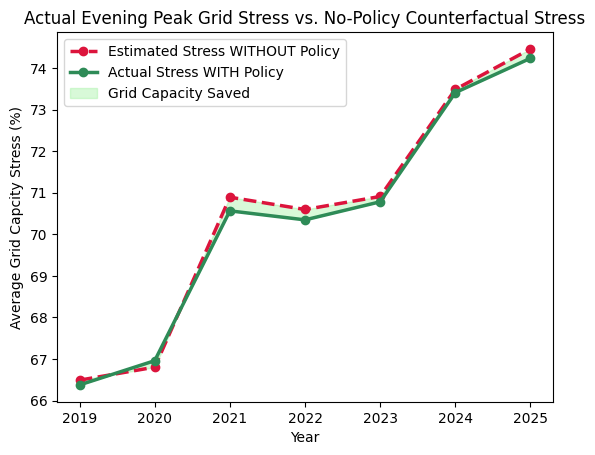

In [103]:
# Checks with current policy zones to simulate past years if policy was never implemented in each area
policy_evenings = ev_grid_working[
    (ev_grid_working["Zone_Name"].isin(policy_zones))
    & (ev_grid_working["Time_Block"] == "Evening_Peak")
].copy()
grid_alternate_no_policy = policy_evenings.copy()
grid_alternate_no_policy["Policy_Numeric"]=0

features = [
    "Homes_in_Zone",
    "EV_Share_Pct",
    "Public_Charger_Count",
    "Avg_Temp_F",
    "Grid_Capacity_MW",
    "Policy_Numeric",
]

policy_evenings["Counterfactual_No_Policy_Stress"] = (discount_simulation_model.predict(grid_alternate_no_policy[features]))
yearly_savings = (
    policy_evenings.groupby("Year")[[
        "Total_Stress_Pct",
        "Counterfactual_No_Policy_Stress",
    ]]
    .mean()
    .reset_index()
)

# Plots both actual stress with policy, and simulated stress without policy
plt.plot(
    yearly_savings["Year"],
    yearly_savings["Counterfactual_No_Policy_Stress"],
    label="Estimated Stress WITHOUT Policy",
    color="crimson",
    linestyle="--",
    marker="o",
    linewidth=2.5,
)
plt.plot(
    yearly_savings["Year"],
    yearly_savings["Total_Stress_Pct"],
    label="Actual Stress WITH Policy",
    color="seagreen",
    marker="o",
    linewidth=2.5,
)

plt.fill_between(
    yearly_savings["Year"],
    yearly_savings["Total_Stress_Pct"],
    yearly_savings["Counterfactual_No_Policy_Stress"],
    color="lightgreen",
    alpha=0.35,
    label="Grid Capacity Saved",
)

plt.gca().set(
    title = "Actual Evening Peak Grid Stress vs. No-Policy Counterfactual Stress",
    xlabel = "Year", ylabel="Average Grid Capcity Stress (%)"
)
plt.legend()
plt.savefig("saved_stress_with_fake_no_discount_graph.png", dpi=300, bbox_inches="tight")

# Model Analysis
To try and understand what caused variation within the results, adoption rates were graphed.
* Adoption rates across policy zones were graphed to try and understand why the discount was more successful in 2021-2023 compared to other years.
* Adoption rates across no policy zones were graphed to try and understand why one zone had an increase in stress instead of a decrease when the policy was implemented

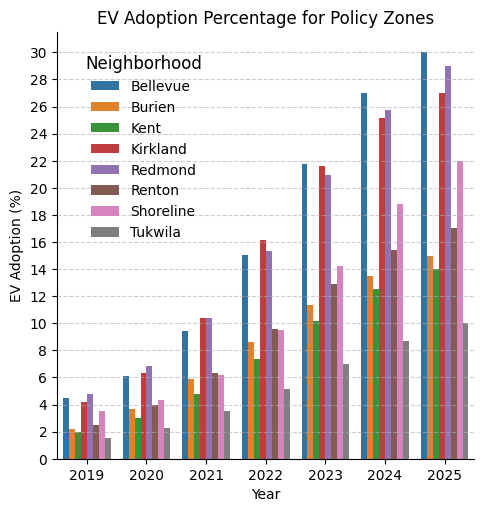

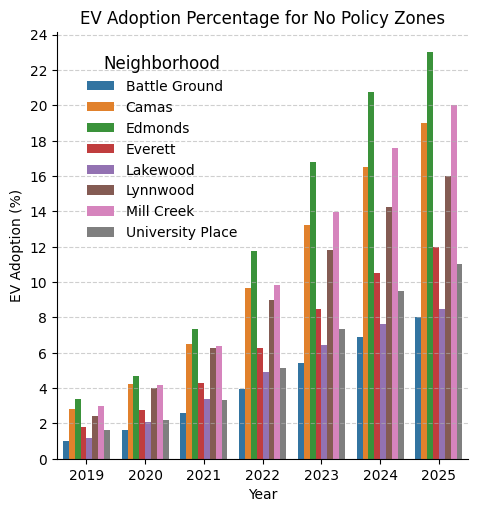

In [104]:
import matplotlib.ticker as ticker

# Checks EV adoption rates in each policy zone
ev_adoption_rates_discount = ev_grid_working[ev_grid_working["Zone_Name"].isin(policy_zones)].groupby(["Zone_Name", "Year"])["EV_Share_Pct"].mean().reset_index()
ev_adoption_rates_discount_graph = sns.catplot(ev_adoption_rates_discount, x="Year", y="EV_Share_Pct", hue="Zone_Name", kind="bar")
ev_adoption_rates_discount_graph.set(title="EV Adoption Percentage for Policy Zones", xlabel="Year", ylabel="EV Adoption (%)")
ev_adoption_rates_discount_graph.ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
ev_adoption_rates_discount_graph.ax.grid(True, linestyle="--", alpha=0.6, axis="y")
sns.move_legend(ev_adoption_rates_discount_graph,  loc="upper left",
    title="Neighborhood",
    bbox_to_anchor=(0.15, 0.95),
    fontsize=10,
    title_fontsize=12)
plt.savefig("ev_adoption_comparing_policy_graph.png", dpi=300, bbox_inches="tight")

# Checks EV adoption rates in each no policy zone
ev_adoption_rates_no_discount = ev_grid_working[~ev_grid_working["Zone_Name"].isin(policy_zones)].groupby(["Zone_Name", "Year"])["EV_Share_Pct"].mean().reset_index()
ev_adoption_rates_no_discount_graph = sns.catplot(ev_adoption_rates_no_discount, x="Year", y="EV_Share_Pct", hue="Zone_Name", kind="bar")
ev_adoption_rates_no_discount_graph.set(title="EV Adoption Percentage for No Policy Zones", xlabel="Year", ylabel="EV Adoption (%)")
ev_adoption_rates_no_discount_graph.ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
ev_adoption_rates_no_discount_graph.ax.grid(True, linestyle="--", alpha=0.6, axis="y")
sns.move_legend(ev_adoption_rates_no_discount_graph,  loc="upper left",
    title="Neighborhood",
    bbox_to_anchor=(0.15, 0.95),
    fontsize=10,
    title_fontsize=12)
plt.savefig("ev_adoption_comparing_no_policy_graph.png", dpi=300, bbox_inches="tight")